# Imputation

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

## Experiment

Define output of experiment:

In [2]:
OUTPUTS = PROJECT_ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

Import data, split into train/test and scale on train data.

In [3]:
from src.data import load_ett, chronological_split, scale

train, test = chronological_split(load_ett())
train_s, test_s, scaler = scale(train=train, test=test)

Set location for storing reconstructed datasets.

In [4]:
from src.experiments.artifacts import ReconstructedStore

store = ReconstructedStore(OUTPUTS / "reconstructed")

Initialise experiment.

In [5]:
from src.experiments.imputation import ImputationExperiment
from src.imputers import IMPUTERS

c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



████████╗██╗███╗   ███╗███████╗    ███████╗███████╗██████╗ ██╗███████╗███████╗    █████╗ ██╗
╚══██╔══╝██║████╗ ████║██╔════╝    ██╔════╝██╔════╝██╔══██╗██║██╔════╝██╔════╝   ██╔══██╗██║
   ██║   ██║██╔████╔██║█████╗█████╗███████╗█████╗  ██████╔╝██║█████╗  ███████╗   ███████║██║
   ██║   ██║██║╚██╔╝██║██╔══╝╚════╝╚════██║██╔══╝  ██╔══██╗██║██╔══╝  ╚════██║   ██╔══██║██║
   ██║   ██║██║ ╚═╝ ██║███████╗    ███████║███████╗██║  ██║██║███████╗███████║██╗██║  ██║██║
   ╚═╝   ╚═╝╚═╝     ╚═╝╚══════╝    ╚══════╝╚══════╝╚═╝  ╚═╝╚═╝╚══════╝╚══════╝╚═╝╚═╝  ╚═╝╚═╝
ai4ts v0.0.3 - building AI for unified time-series analysis, https://time-series.ai 



In [6]:
experiment_cheap = ImputationExperiment(
    mechanisms=["mar", "mcar", "mnar"],
    proportions=[10, 30, 50],
    seeds=range(10),
    imputer_names=["mean","locf","ks"]
)

experiment_cheap.run(train=train_s, store=store)

imputation:  10%|█         | 27/270 [00:34<05:05,  1.26s/it]c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
imputation:  30%|███       | 81/270 [01:46<04:06,  1.30s/it]c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
imputation:  41%|████      | 111/270 [02:26<03:29,  1.31s/it]c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmode

,mechanism,proportion,seed,imputer,reconstruction_rmse,reconstruction_mae
0,mar,10,0,mean,0.143965,0.111359
1,mar,10,0,locf,0.049497,0.032298
2,mar,10,0,ks,0.035401,0.023712
3,mar,30,0,mean,0.157178,0.125866
4,mar,30,0,locf,0.058453,0.038822
...,...,...,...,...,...,...
265,mnar,30,9,locf,0.059888,0.039745
266,mnar,30,9,ks,0.043306,0.029049
267,mnar,50,9,mean,0.193984,0.167411
268,mnar,50,9,locf,0.079672,0.054242


In [6]:
experiment_arima = ImputationExperiment(
    mechanisms=["mar", "mcar", "mnar"],
    proportions=[10, 30, 50],
    seeds=range(10),
    imputer_names=["arima"]
)

experiment_arima.run(train=train_s, store=store)

imputation:   1%|          | 1/90 [03:08<4:39:09, 188.20s/it]c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
imputation:  24%|██▍       | 22/90 [1:09:22<3:32:57, 187.90s/it]c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
imputation:  73%|███████▎  | 66/90 [3:30:19<1:18:56, 197.36s/it]c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
imputation:  78%|███████▊  | 70/90 [3:43:41<1:04:25, 193.25s/it]c:\

,mechanism,proportion,seed,imputer,reconstruction_rmse,reconstruction_mae
0,mar,10,0,arima,0.031353,0.020931
1,mar,30,0,arima,0.034902,0.023793
2,mar,50,0,arima,0.045834,0.031025
3,mcar,10,0,arima,0.033112,0.021287
4,mcar,30,0,arima,0.035160,0.022747
...,...,...,...,...,...,...
85,mcar,30,9,arima,0.035018,0.022677
86,mcar,50,9,arima,0.038576,0.025241
87,mnar,10,9,arima,0.032958,0.021308
88,mnar,30,9,arima,0.036166,0.024116


In [7]:
experiment_brits = ImputationExperiment(
    mechanisms=["mar", "mcar", "mnar"],
    proportions=[10, 30, 50],
    seeds=range(10),
    imputer_names=["brits"]
)

experiment_brits.run(train=train_s, store=store)

imputation:   0%|          | 0/90 [00:00<?, ?it/s]2026-07-10 22:54:09 [INFO]: Have set the random seed as 0 for numpy and pytorch.
2026-07-10 22:54:09 [WARNING]: ‼️ saving_path not given. Model files and tensorboard file will not be saved.
imputation: 100%|██████████| 90/90 [17:49:50<00:00, 713.23s/it]


,mechanism,proportion,seed,imputer,reconstruction_rmse,reconstruction_mae
0,mar,10,0,brits,0.033154,0.018970
1,mar,30,0,brits,0.039888,0.024871
2,mar,50,0,brits,0.058161,0.037293
3,mcar,10,0,brits,0.030036,0.017398
4,mcar,30,0,brits,0.035164,0.021402
...,...,...,...,...,...,...
85,mcar,30,9,brits,0.035423,0.021246
86,mcar,50,9,brits,0.041533,0.026565
87,mnar,10,9,brits,0.035211,0.019627
88,mnar,30,9,brits,0.040098,0.024436


## Results

Rebuild from reconstructed datasets.

In [5]:
import pandas as pd
from dataclasses import asdict
from src.missingness import create_mask
from src.evaluation import reconstruction_errors
from src.experiments.artifacts import ExperimentRun

rows = []
for k in store.keys():
    mask = create_mask(train_s, k.mechanism, k.proportion, k.seed)
    imputed = store.get(k)
    rmse, mae = reconstruction_errors(train_s, imputed, mask)
    rows.append(ExperimentRun(k.mechanism, k.proportion, k.seed, k.imputer, rmse, mae))

recon_df = pd.DataFrame([asdict(r) for r in rows])
recon_df.to_parquet(OUTPUTS / "reconstruction_metrics.parquet")

In [5]:
import pandas as pd
df = pd.read_parquet(OUTPUTS / "reconstruction_metrics.parquet")

In [7]:
df.groupby(["imputer", "mechanism", "proportion"]).agg(
    rmse=("reconstruction_rmse", "mean"),
    mae=("reconstruction_mae", "mean")
    )

rmse       mae
imputer mechanism proportion                    
arima   mar       10          0.031333  0.020876
                  30          0.035314  0.023768
                  50          0.046100  0.031050
        mcar      10          0.033346  0.021317
                  30          0.034806  0.022723
                  50          0.038249  0.025275
        mnar      10          0.031967  0.021326
                  30          0.036399  0.024320
                  50          0.047935  0.031628
brits   mar       10          0.032858  0.018767
                  30          0.040205  0.024786
                  50          0.057405  0.036837
        mcar      10          0.030094  0.017397
                  30          0.035074  0.021336
                  50          0.041793  0.026626
        mnar      10          0.032994  0.019129
                  30          0.040426  0.024888
                  50          0.058653  0.037002
ks      mar       10          0.035238  0.023531
                  30          0.042119  0.028243
                  50          0.060891  0.040751
        mcar      10          0.037036  0.024020
                  30          0.039914  0.026227
                  50          0.046734  0.030576
        mnar      10          0.036130  0.024240
                  30          0.043445  0.029063
                  50          0.061681  0.041215
locf    mar       10          0.048911  0.032286
                  30          0.058830  0.038996
                  50          0.078174  0.053210
        mcar      10          0.054085  0.034353
                  30          0.061268  0.038359
                  50          0.072965  0.045074
        mnar      10          0.049814  0.033123
                  30          0.059849  0.039895
                  50          0.078907  0.053790
mean    mar       10          0.144442  0.112215
                  30          0.156675  0.125496
                  50          0.180419  0.150742
        mcar      10          0.147382  0.110098
                  30          0.147117  0.109911
                  50          0.147228  0.110014
        mnar      10          0.143391  0.110934
                  30          0.161636  0.131070
                  50          0.193669  0.167215

In [ ]:
from src.figures_cfg import (apply_theme, plot_reconstruction, IMPUTER_COLORS,
                         IMPUTER_ORDER, MECHANISM_ORDER, MECHANISM_TITLES)
apply_theme()

### Imputer MAE

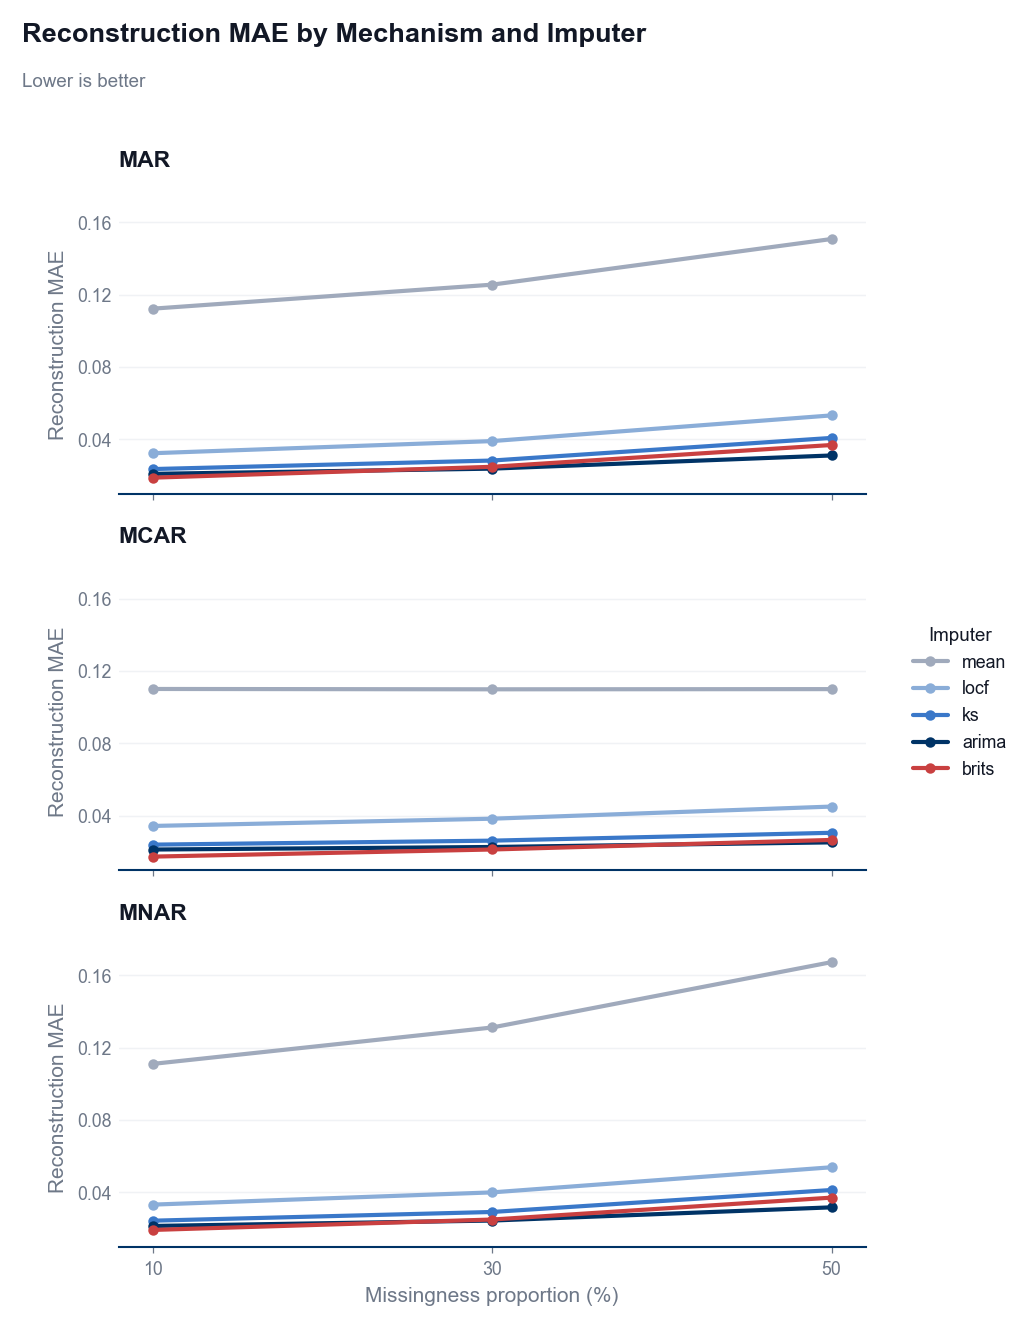

In [21]:
fig = plot_reconstruction(
    df, x="proportion", y="reconstruction_mae",
    panel="mechanism", series="imputer",
    layout="vertical",
    panel_order=MECHANISM_ORDER, series_order=IMPUTER_ORDER,
    color_map=IMPUTER_COLORS, panel_titles=MECHANISM_TITLES,
    x_ticks=[10, 30, 50], x_label="Missingness proportion (%)",
    y_label="Reconstruction MAE", legend_title="Imputer",
    suptitle="Reconstruction MAE by Mechanism and Imputer",
    subtitle="Lower is better"
)

fig.savefig(OUTPUTS / "figures/reconstruction/reconstruction_mae_comparison.png")

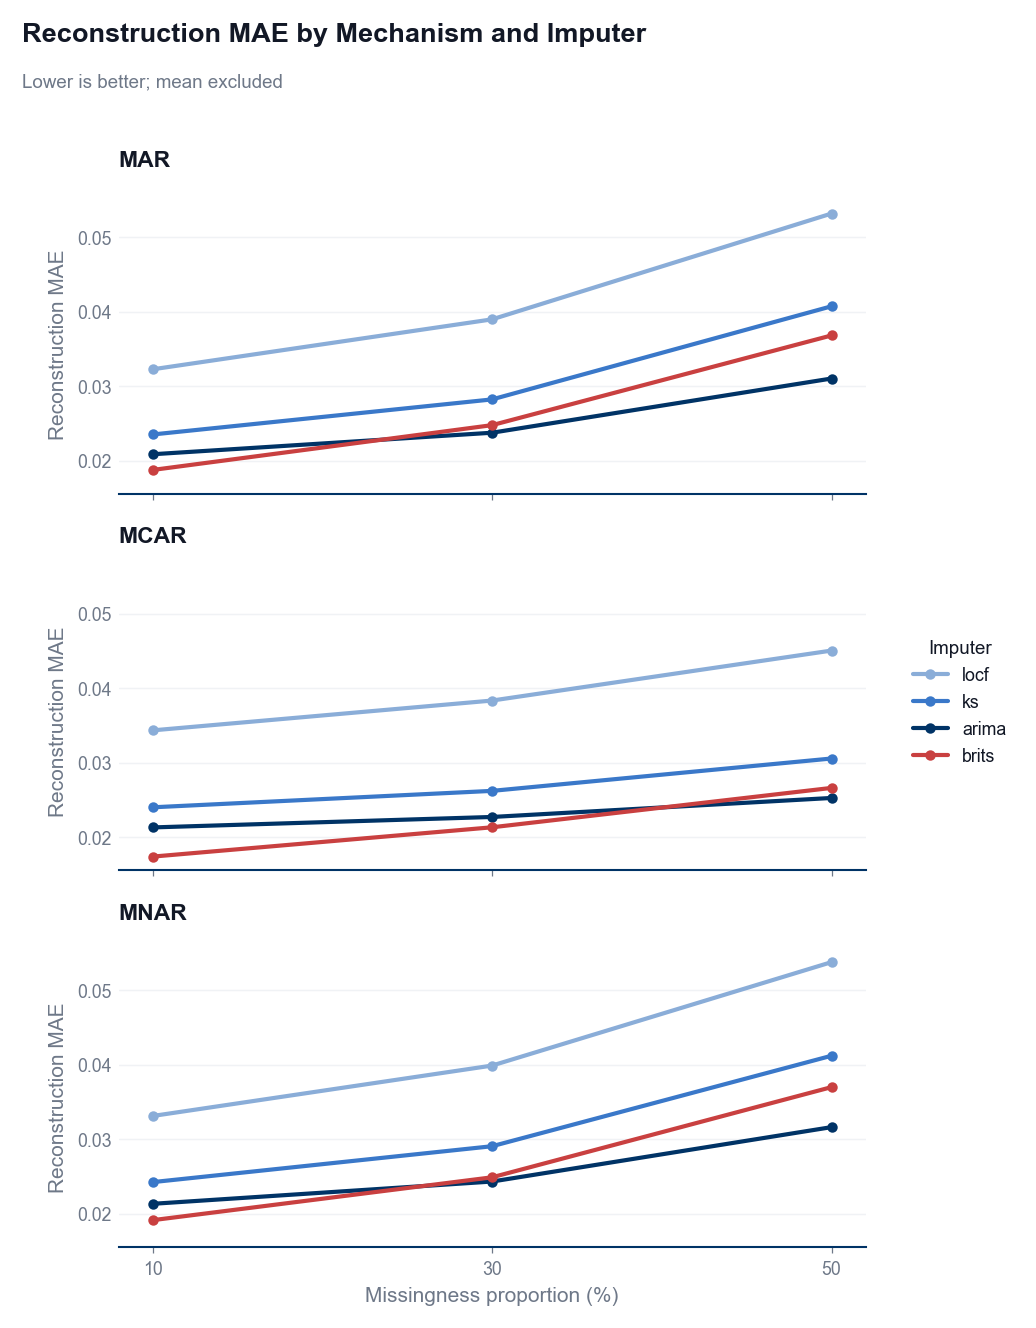

In [22]:
fig = plot_reconstruction(
    df, x="proportion", y="reconstruction_mae",
    panel="mechanism", series="imputer",
    layout="vertical",
    panel_order=MECHANISM_ORDER, series_order=["locf","ks","arima","brits"],
    color_map=IMPUTER_COLORS, panel_titles=MECHANISM_TITLES,
    x_ticks=[10, 30, 50], x_label="Missingness proportion (%)",
    y_label="Reconstruction MAE", legend_title="Imputer",
    suptitle="Reconstruction MAE by Mechanism and Imputer",
    subtitle="Lower is better; mean excluded"
)
fig.savefig(OUTPUTS / "figures/reconstruction/reconstruction_mae_comparison_mean_excluded.png")

### Imputer RMSE

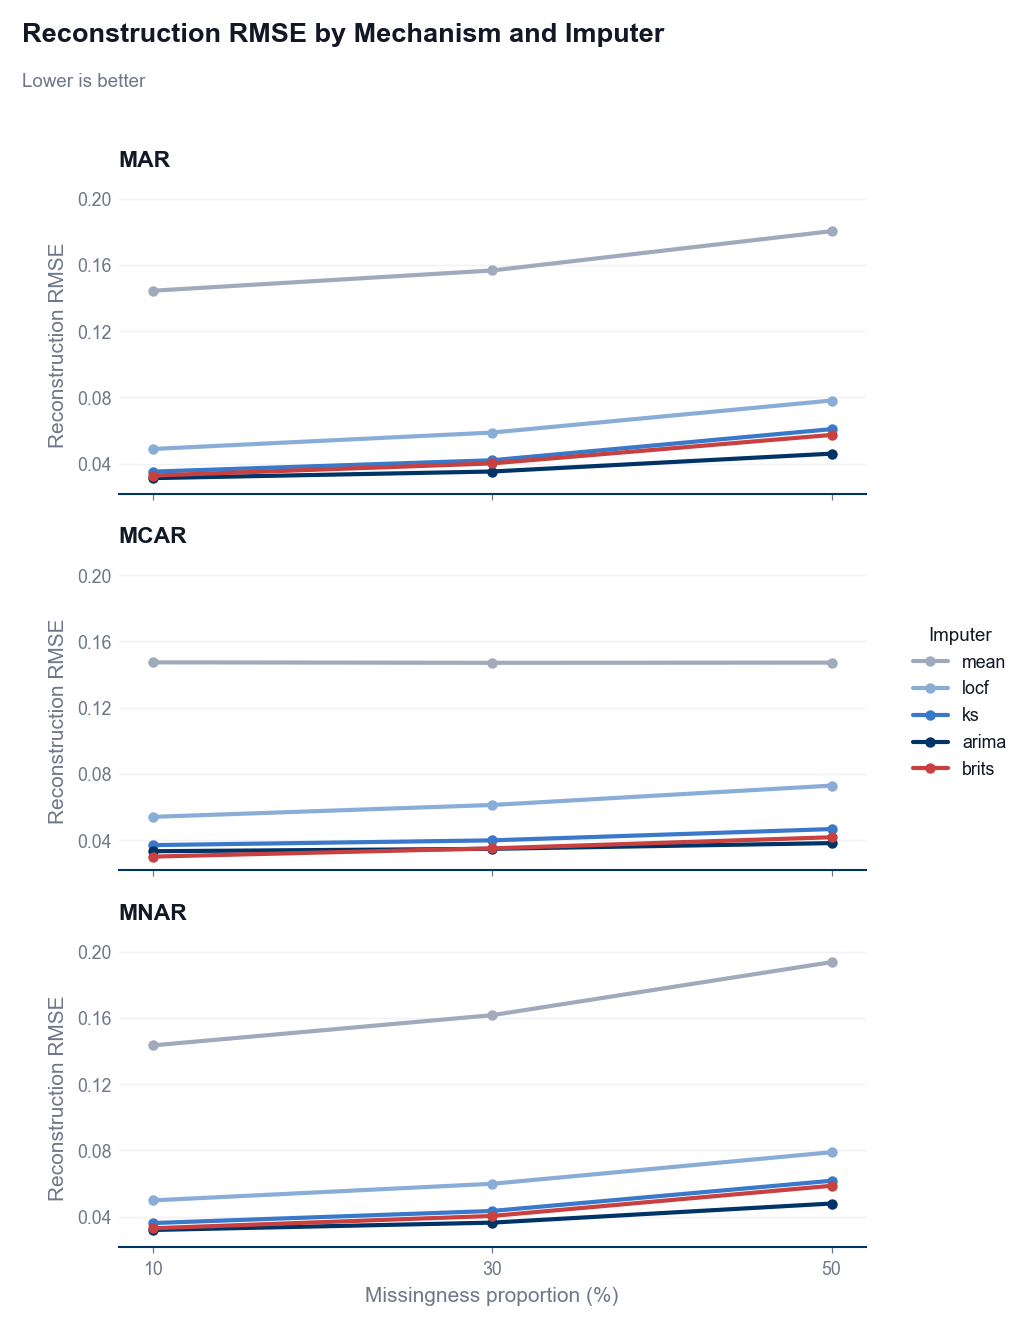

In [23]:
fig = plot_reconstruction(
    df, x="proportion", y="reconstruction_rmse",
    panel="mechanism", series="imputer",
    layout="vertical",
    panel_order=MECHANISM_ORDER, series_order=IMPUTER_ORDER,
    color_map=IMPUTER_COLORS, panel_titles=MECHANISM_TITLES,
    x_ticks=[10, 30, 50], x_label="Missingness proportion (%)",
    y_label="Reconstruction RMSE", legend_title="Imputer",
    suptitle="Reconstruction RMSE by Mechanism and Imputer",
    subtitle="Lower is better"
)

fig.savefig(OUTPUTS / "figures/reconstruction/reconstruction_rmse_comparison.png")

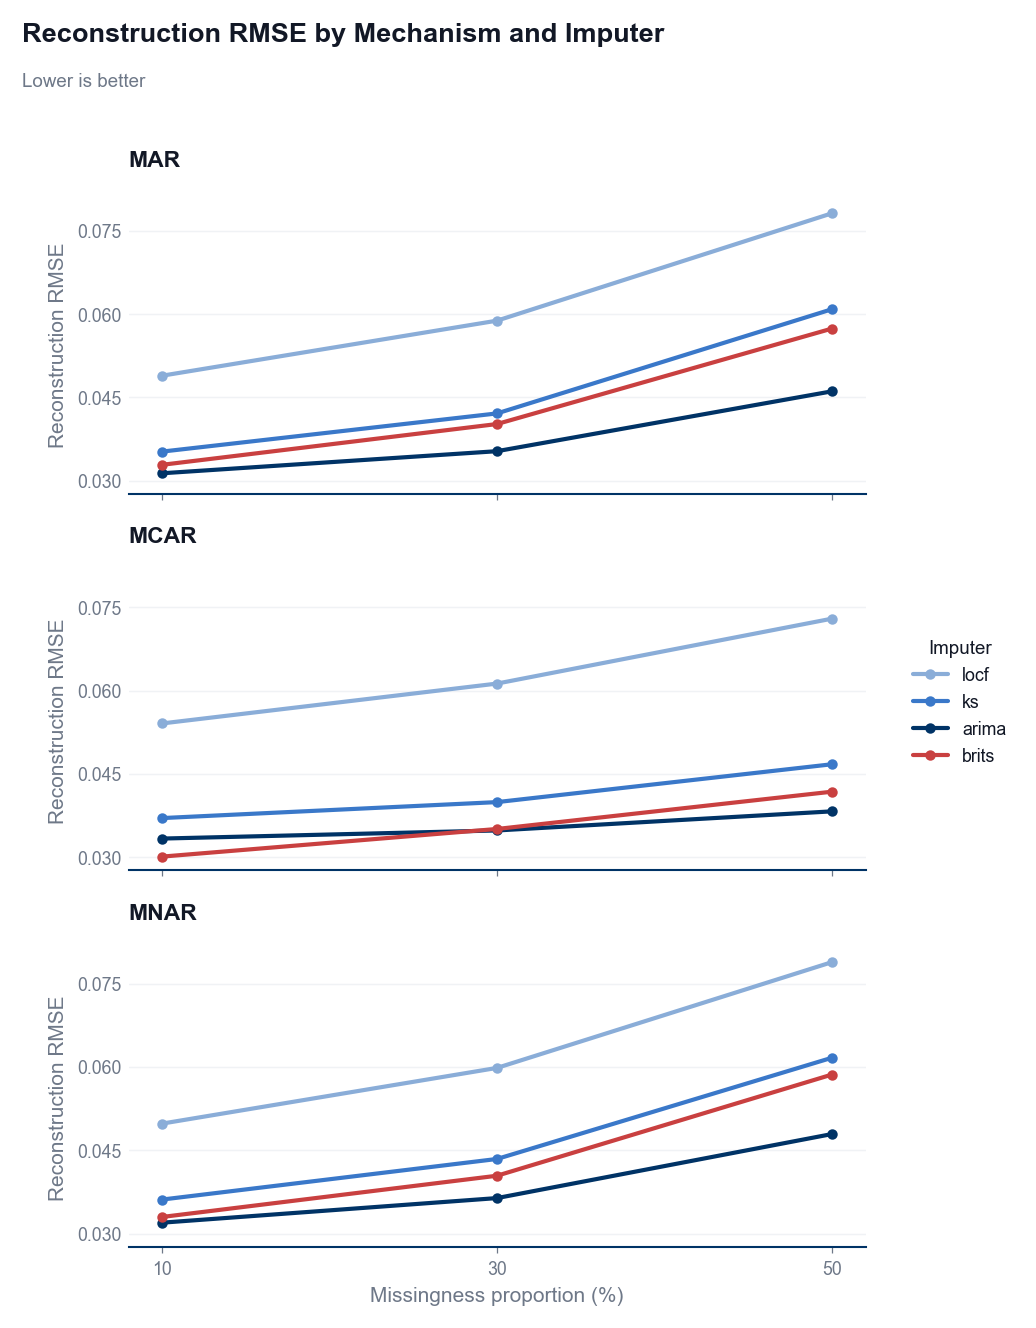

In [24]:
fig = plot_reconstruction(
    df, x="proportion", y="reconstruction_rmse",
    panel="mechanism", series="imputer",
    layout="vertical",
    panel_order=MECHANISM_ORDER, series_order=["locf","ks","arima","brits"],
    color_map=IMPUTER_COLORS, panel_titles=MECHANISM_TITLES,
    x_ticks=[10, 30, 50], x_label="Missingness proportion (%)",
    y_label="Reconstruction RMSE", legend_title="Imputer",
    suptitle="Reconstruction RMSE by Mechanism and Imputer",
    subtitle="Lower is better"
)

fig.savefig(OUTPUTS / "figures/reconstruction/reconstruction_rmse_comparison_mean_excluded.png")

### Mechanism Comparison

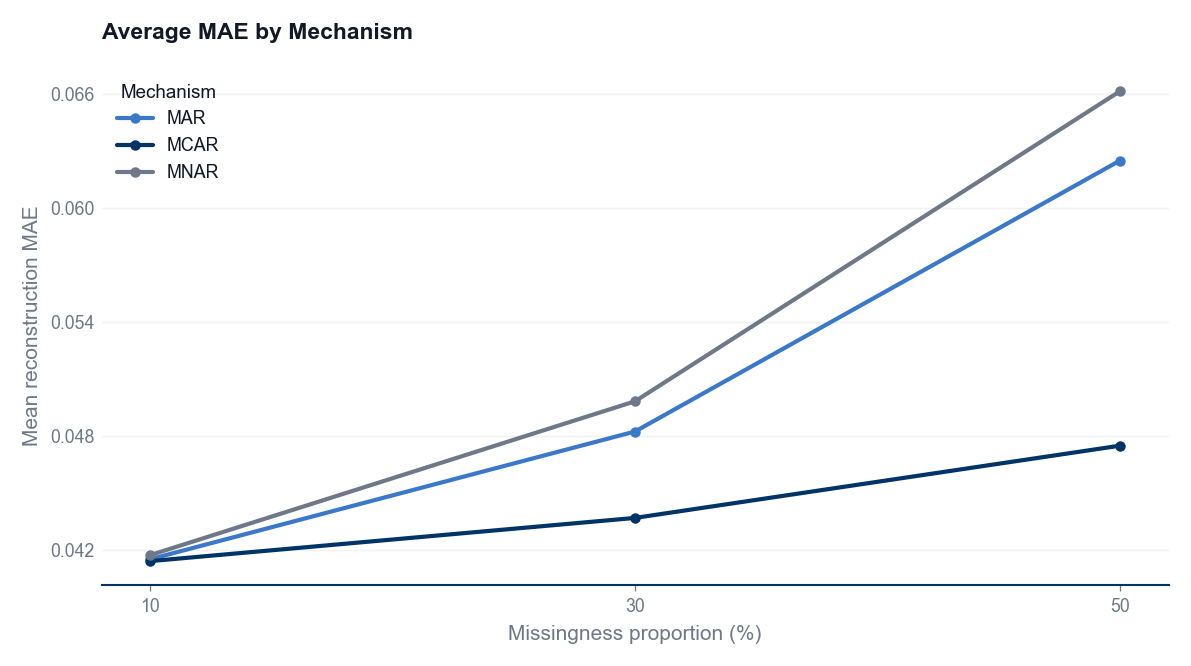

In [41]:
from src.figures_cfg import PRIMARY, MUTED, INK, LIGHT, WHITE, CAT_PAL, ticker
import matplotlib.pyplot as plt

keep = ["mean", "locf", "ks", "arima", "brits"]

agg = (df[df["imputer"].isin(keep)]
       .groupby(["mechanism", "proportion"])["reconstruction_mae"]
       .mean().reset_index(name="mae"))

mech_colors = {"mcar": CAT_PAL[0], "mar": CAT_PAL[1], "mnar": CAT_PAL[2]}

fig, ax = plt.subplots(figsize=(8, 4.5))
for mech in ["mar", "mcar", "mnar"]:
    g = agg[agg["mechanism"] == mech].sort_values("proportion")
    ax.plot(g["proportion"], g["mae"], marker="o", markersize=4,
            color=mech_colors[mech], label=mech.upper())

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color(PRIMARY)
ax.spines["bottom"].set_linewidth(1.0)
ax.grid(axis="y", color=LIGHT, linewidth=0.7)
ax.set_facecolor(WHITE)
ax.set_xticks([10, 30, 50])
ax.tick_params(axis="x", labelsize=8.5, colors=MUTED)
ax.tick_params(axis="y", labelsize=8.5, colors=MUTED)
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5, prune="both"))
ax.set_xlabel("Missingness proportion (%)", color=MUTED, fontsize=10)
ax.set_ylabel("Mean reconstruction MAE", color=MUTED, fontsize=10)
ax.set_title("Average MAE by Mechanism",
             color=INK, fontweight="bold", fontsize=11, loc="left", pad=14)
ax.legend(title="Mechanism", title_fontsize=9, fontsize=8.5,
          frameon=False, labelcolor=INK, loc="upper left")

fig.tight_layout()
fig.savefig(OUTPUTS / "figures/reconstruction/reconstruction_mae_mech-aggregate.png")
plt.show()

# Testing

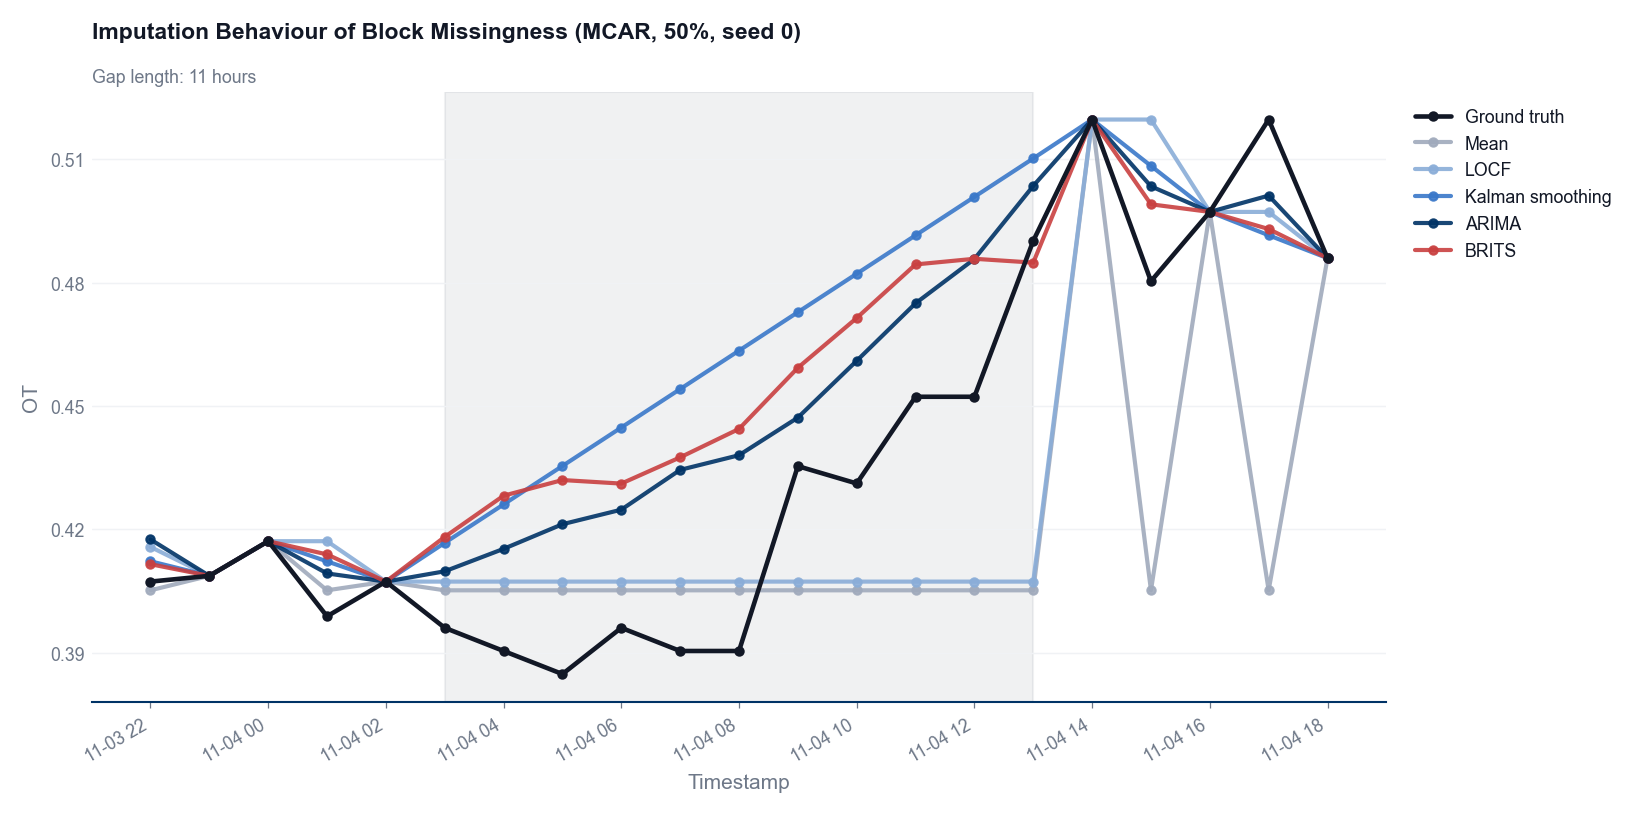

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from src.missingness import create_mask
from src.experiments.artifacts import OriginKey
from src.figures_cfg import (apply_theme, IMPUTER_COLORS, IMPUTER_ORDER,
                         PRIMARY, MUTED, INK, LIGHT, WHITE)

apply_theme()

# --- CONFIG ---
TARGET, PAD = "OT", 5
MECHANISM, PROPORTION, SEED = "mcar", 50, 0

display_names = {"mean": "Mean", "locf": "LOCF", "ks": "Kalman smoothing",
                 "arima": "ARIMA", "brits": "BRITS"}

# 1. Recreate mask + find the longest gap in the target column
mask = create_mask(train_s, MECHANISM, PROPORTION, SEED)
col = train_s[TARGET].mask(mask[TARGET])
nan_pos = np.where(col.isna().to_numpy())[0]
runs = np.split(nan_pos, np.where(np.diff(nan_pos) > 1)[0] + 1)
longest = runs[int(np.argmax([len(r) for r in runs]))]

lo, hi = max(0, longest[0] - PAD), min(len(col), longest[-1] + PAD + 1)
w = np.arange(lo, hi)
t = train_s.index[w]

# 2. Pull each imputer's fill from the store
filled = {}
for imp in IMPUTER_ORDER:
    key = OriginKey(mechanism=MECHANISM, proportion=PROPORTION, seed=SEED, imputer=imp)
    if store.exists(key):
        filled[imp] = store.get(key)
    else:
        print(f"Warning: not in store, skipping -> {key}")

# 3. Plot
fig, ax = plt.subplots(figsize=(11, 5.5))

# shade the gap first (behind the lines)
ax.axvspan(train_s.index[longest[0]], train_s.index[longest[-1]],
           color=MUTED, alpha=0.10, zorder=0)

# ground truth
ax.plot(t, train_s[TARGET].to_numpy()[w], "o-", label="Ground truth",
        color=INK, linewidth=2.2, markersize=4, zorder=5)

# each imputer, coloured by the canonical palette
for imp in IMPUTER_ORDER:
    if imp not in filled:
        continue
    ax.plot(t, filled[imp][TARGET].to_numpy()[w], marker="o", markersize=4,
            color=IMPUTER_COLORS[imp], alpha=0.9, label=display_names[imp])

# theme styling
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)
ax.spines["bottom"].set_color(PRIMARY)
ax.spines["bottom"].set_linewidth(1.0)
ax.grid(axis="y", color=LIGHT, linewidth=0.7)
ax.set_facecolor(WHITE)
ax.tick_params(axis="x", labelsize=8.5, colors=MUTED)
ax.tick_params(axis="y", labelsize=8.5, colors=MUTED)
ax.yaxis.set_major_locator(ticker.MaxNLocator(nbins=5, prune="both"))

ax.set_xlabel("Timestamp", color=MUTED, fontsize=10)
ax.set_ylabel(TARGET, color=MUTED, fontsize=10)
ax.set_title(f"Imputation Behaviour of Block Missingness ({MECHANISM.upper()}, {PROPORTION}%, seed {SEED})",
             color=INK, fontweight="bold", fontsize=11, loc="left", pad=26)
ax.text(0, 1.01, f"Gap length: {len(longest)} hours", transform=ax.transAxes,
        color=MUTED, fontsize=8.5, va="bottom")

# legend outside, right
ax.legend(frameon=False, fontsize=8.5, labelcolor=INK,
          bbox_to_anchor=(1.01, 1), loc="upper left")

fig.autofmt_xdate(rotation=30, ha="right")
fig.tight_layout()
fig.savefig(OUTPUTS / "figures/reconstruction/block_missingness_imputation.png")
plt.show()